# Pronóstico de demanda: resultados y conclusiones

Este notebook presenta el caso de principio a fin: el problema, los datos, la demanda histórica, la comparación de modelos, las métricas, la utilidad para inventario y las conclusiones.

Los datos son sintéticos. La implementación del modelo de pronóstico no se publica en este repositorio; aquí se muestran sus resultados.

## 1. Datos

Las ventas están en SQLite. La vista `v_ventas_detalle` (en `sql/analisis_ventas.sql`) calcula el ingreso de cada venta como `cantidad × precio × (1 − descuento)` y la une con sucursales y productos.

In [1]:
from pathlib import Path
import sqlite3

import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()

with sqlite3.connect(RAIZ / "data" / "ventas.db") as conexion:
    conexion.executescript((RAIZ / "sql" / "analisis_ventas.sql").read_text(encoding="utf-8").split("-- 1.")[0])
    demanda = pd.read_sql_query(
        "SELECT mes, SUM(cantidad) AS unidades FROM v_ventas_detalle GROUP BY mes ORDER BY mes",
        conexion,
    )

demanda["mes"] = pd.PeriodIndex(demanda["mes"], freq="M").to_timestamp()
demanda.set_index("mes").tail(6)

,unidades
mes,
2025-07-01,611
2025-08-01,599
2025-09-01,549
2025-10-01,576
2025-11-01,683
2025-12-01,974


## 2. Demanda histórica

La demanda sube en mayo y, sobre todo, en noviembre y diciembre. Ese patrón se repite en 2024 y 2025, por eso el pronóstico necesita modelar la estacionalidad.

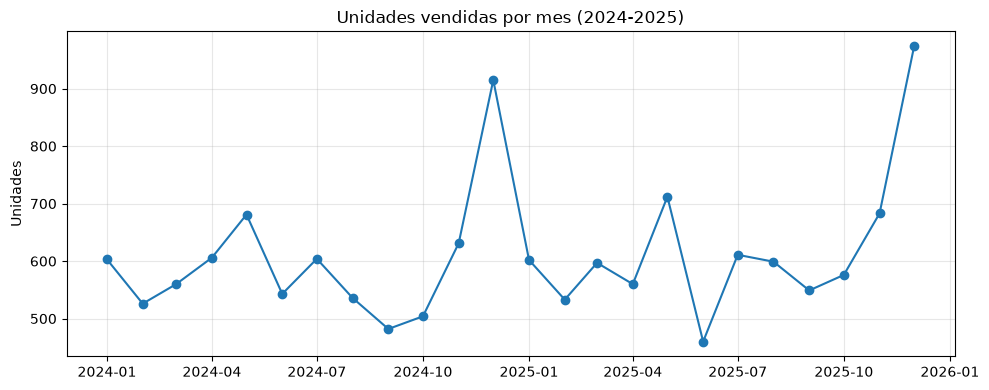

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(demanda["mes"], demanda["unidades"], marker="o")
ax.set_title("Unidades vendidas por mes (2024-2025)")
ax.set_ylabel("Unidades")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 3. Comparación de modelos

Se entrenó con todo menos los últimos 3 meses (octubre a diciembre de 2025) y se midió contra esos meses reales. Se comparan dos enfoques:

- **Línea base:** promedio de los últimos 3 meses de entrenamiento.
- **Modelo estacional:** demanda del mismo mes del año anterior, ajustada por la tendencia interanual.

| Modelo | MAE (unidades) | MAPE |
|---|---|---|
| Línea base | 164.9 | 18.6 % |
| Modelo estacional | **50.1** | **7.3 %** |

El MAE es el error medio en unidades; el MAPE es el error medio en porcentaje del real.

![Real frente a pronóstico](pronostico_demanda.png)

## 4. Utilidad para inventario

La línea base no ve el repunte de fin de año: subestima diciembre en más de 380 unidades. Si se compra con esa línea base, el inventario de diciembre se queda corto. El modelo estacional reduce el error a menos de la mitad.

**Proyección para enero a marzo de 2026:** entre 550 y 625 unidades mensuales en total (624, 553 y 619). Sirve como punto de partida para la compra, no como cifra exacta.

## 5. Conclusiones

- Electrónica genera 6.8 millones de pesos, casi el doble que Hogar. Los 10 productos principales concentran 90.2 % del ingreso.
- Las sucursales de Polanco y Santa Fe (CDMX) generan 25.1 % del ingreso, con 2 de 8 sucursales.
- Un modelo que captura la estacionalidad reduce el error de 18.6 % a 7.3 % frente a una línea base simple.

**Límites:** los datos son sintéticos, la prueba cubre solo 3 meses y el pronóstico es del total mensual. Para planear por sucursal o producto hace falta más historia por grupo.